In [1]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import rdf
from openff.toolkit import Molecule, Topology
from openff.units import unit as ffunit
from openff.toolkit import Molecule, ForceField
from openff.interchange import Interchange
from openff.interchange.components._packmol import pack_box, RHOMBIC_DODECAHEDRON
import mdtraj as md
from scipy.signal import savgol_filter
from scipy.integrate import simpson

In [2]:
ligand = Molecule('./data/7378987.sdf')
water = Molecule.from_smiles("[H][O][H]")
for atom in water.atoms:
    atom.metadata["residue_name"] = "HOH"
fftop = pack_box(
    molecules=[ligand, water],
    number_of_copies=[1, 1000],
    box_vectors=35 * RHOMBIC_DODECAHEDRON * ffunit.angstrom)
sage = ForceField("openff_unconstrained-2.1.0.offxml", "tip3p.offxml")
interchange: Interchange = Interchange.from_smirnoff(force_field=sage, topology=fftop)
ligand_mol = fftop.molecule(0)
start = fftop.molecule_atom_start_index(ligand_mol)
n_ligand_atoms = ligand_mol.n_atoms
lig_idx = list(range(start, start + n_ligand_atoms))


In [3]:
target_atoms = {
    0: 'Oxygen (Idx 0)',
    1: 'Oxygen (Idx 1)',
    5: 'Nitrogen (Idx 5)'
}
omm_topology = interchange.to_openmm_topology()
md_top = md.Topology.from_openmm(omm_topology)

In [5]:
MM_coords = np.load("./data/coords_mm.npz")['coord']
MM_box = np.load("./data/box_mm.npz")['box']

fix_coords = np.load("./data/coords_me.npz")['coord']
fix_box = np.load("./data/box_me.npz")['box']

coords_10 = np.load("./data/coords_enME10.npz")['coord']
box_10 = np.load("./data/box_enME10.npz")['box']

coords_12 = np.load("./data/coords_enME12.npz")['coord']
box_12 = np.load("./data/box_enME12.npz")['box']

In [7]:
MM_traj = md.Trajectory(MM_coords, md_top)
MM_traj.unitcell_vectors = MM_box

ML_fix_traj = md.Trajectory(fix_coords, md_top)
ML_fix_traj.unitcell_vectors = fix_box

ML_10_traj = md.Trajectory(coords_10, md_top)
ML_10_traj.unitcell_vectors = box_10

ML_12_traj = md.Trajectory(coords_12, md_top)
ML_12_traj.unitcell_vectors = box_12

In [8]:
def compute_hbond_number(traj, r, g_r, target_indices, r_cut=0.25):

    avg_volume = np.mean(traj.unitcell_volumes)
    n_target_atoms = len(target_indices)
    rho = n_target_atoms / avg_volume
    
    mask = r <= r_cut
    r_int = r[mask]
    g_r_int = g_r[mask]
    
    integrand = g_r_int * (r_int**2)

    integral_area = simpson(integrand, x=r_int) 

    n_hbonds = 4 * np.pi * rho * integral_area
    
    return n_hbonds

In [9]:
# first h-bond plot
ligand_oxygen_indices = 0

# MM 
water_hydrogen_indices = MM_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_MM, g_r_MM = md.compute_rdf(MM_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-fix 
water_hydrogen_indices = ML_fix_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_ML_fix, g_r_ML_fix = md.compute_rdf(ML_fix_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-1.0
water_hydrogen_indices = ML_10_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_ML_10, g_r_ML_10 = md.compute_rdf(ML_10_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-1.2
water_hydrogen_indices = ML_12_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 

r_ML_12, g_r_ML_12 = md.compute_rdf(ML_12_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

window = 7
poly = 3

g_r_MM_smooth = savgol_filter(g_r_MM, window_length=window, polyorder=poly)
g_r_ML_fix_smooth = savgol_filter(g_r_ML_fix, window_length=window, polyorder=poly)
g_r_ML_10_smooth = savgol_filter(g_r_ML_10, window_length=window, polyorder=poly)
g_r_ML_12_smooth = savgol_filter(g_r_ML_12, window_length=window, polyorder=poly)

cutoff_distance = 0.245 

n_MM = compute_hbond_number(MM_traj, r_MM, g_r_MM, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_fix = compute_hbond_number(ML_fix_traj, r_ML_fix, g_r_ML_fix, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_10 = compute_hbond_number(ML_10_traj, r_ML_10, g_r_ML_10, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_12 = compute_hbond_number(ML_12_traj, r_ML_12, g_r_ML_12, water_hydrogen_indices, r_cut=cutoff_distance)

print(f"MM simulation:                  {n_MM:.2f}")
print(f"ML simulation (ME):   {n_ML_fix:.2f}")
print(f"ML simulation (dynamic x=1.0):  {n_ML_10:.2f}")
print(f"ML simulation (dynamic x=1.2):  {n_ML_12:.2f}")


MM simulation:                  1.78
ML simulation (ME):   1.75
ML simulation (dynamic x=1.0):  1.11
ML simulation (dynamic x=1.2):  1.42


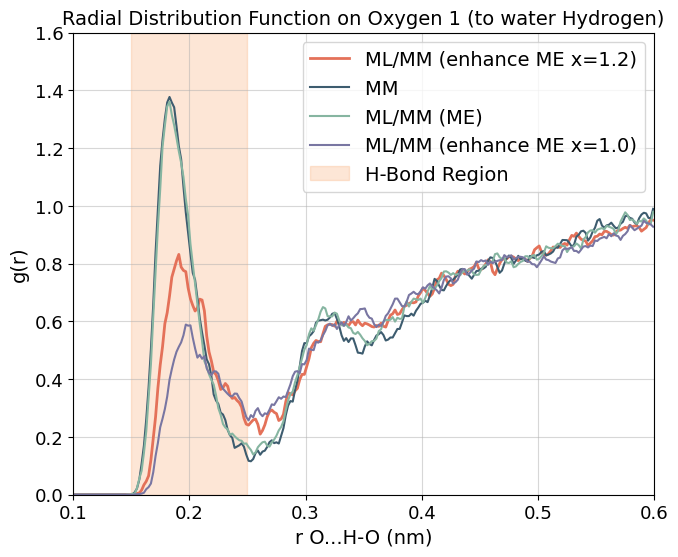

In [10]:
plt.figure(figsize=(7.5, 6))
target_name = "Atom 1" 
plt.plot(r_ML_12, g_r_ML_12_smooth, lw=2, label=f'ML/MM (enhance ME x=1.2)',color = '#E47159')
plt.plot(r_MM, g_r_MM_smooth, lw=1.5, label=f'MM ',color = '#3D5C6F')
plt.plot(r_ML_fix, g_r_ML_fix_smooth, lw=1.5, label=f'ML/MM (ME)',color = '#86B5a1')
plt.plot(r_ML_10, g_r_ML_10_smooth, lw=1.5, label=f'ML/MM (enhance ME x=1.0)',color = '#7976a2')

plt.axvspan(0.15, 0.25, color='#f9ae78', alpha=0.3, label='H-Bond Region')
plt.title('Radial Distribution Function on Oxygen 1 (to water Hydrogen)',fontsize = 14)
plt.xlabel('r O...H-O (nm)',fontsize = 14)
plt.ylabel('g(r)',fontsize = 14)
plt.ylim(0,1.6)
plt.xlim(0.1,0.6)
plt.legend(fontsize = 14)
plt.grid(True, alpha=0.5)
plt.tick_params(axis='y', labelsize=13)
plt.tick_params(axis='x', labelsize=13)
# plt.savefig("Hbond_O1_to_H.svg", dpi = 300)
plt.show()

In [11]:
# second oxygen
ligand_oxygen_indices = 1

# MM 
water_hydrogen_indices = MM_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_MM, g_r_MM = md.compute_rdf(MM_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-fix 
water_hydrogen_indices = ML_fix_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_ML_fix, g_r_ML_fix = md.compute_rdf(ML_fix_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-1.0
water_hydrogen_indices = ML_10_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_ML_10, g_r_ML_10 = md.compute_rdf(ML_10_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-1.2
water_hydrogen_indices = ML_12_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 

r_ML_12, g_r_ML_12 = md.compute_rdf(ML_12_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

window = 7
poly = 3

g_r_MM_smooth = savgol_filter(g_r_MM, window_length=window, polyorder=poly)
g_r_ML_fix_smooth = savgol_filter(g_r_ML_fix, window_length=window, polyorder=poly)
g_r_ML_10_smooth = savgol_filter(g_r_ML_10, window_length=window, polyorder=poly)
g_r_ML_12_smooth = savgol_filter(g_r_ML_12, window_length=window, polyorder=poly)

cutoff_distance = 0.245 

n_MM = compute_hbond_number(MM_traj, r_MM, g_r_MM, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_fix = compute_hbond_number(ML_fix_traj, r_ML_fix, g_r_ML_fix, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_10 = compute_hbond_number(ML_10_traj, r_ML_10, g_r_ML_10, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_12 = compute_hbond_number(ML_12_traj, r_ML_12, g_r_ML_12, water_hydrogen_indices, r_cut=cutoff_distance)

print(f"MM simulation:                  {n_MM:.2f}")
print(f"ML simulation (ME):   {n_ML_fix:.2f}")
print(f"ML simulation (dynamic x=1.0):  {n_ML_10:.2f}")
print(f"ML simulation (dynamic x=1.2):  {n_ML_12:.2f}")


MM simulation:                  1.72
ML simulation (ME):   1.70
ML simulation (dynamic x=1.0):  1.01
ML simulation (dynamic x=1.2):  1.29


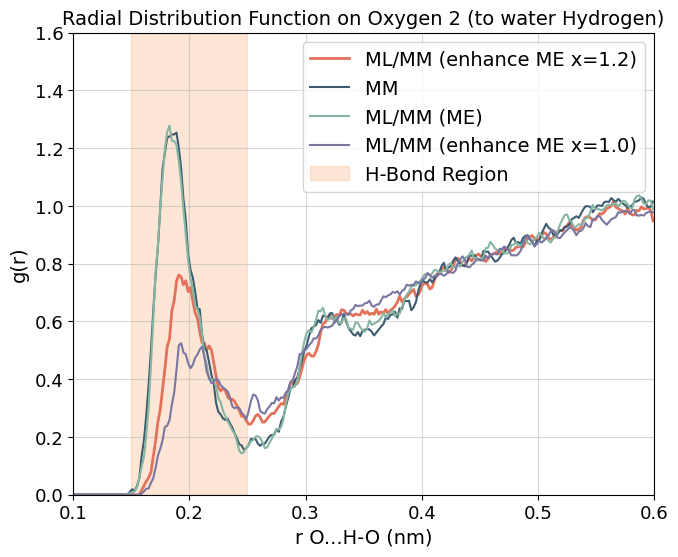

In [12]:
plt.figure(figsize=(7.5, 6))
target_name = "Atom 1" 
plt.plot(r_ML_12, g_r_ML_12_smooth, lw=2, label=f'ML/MM (enhance ME x=1.2)',color = '#E47159')
plt.plot(r_MM, g_r_MM_smooth, lw=1.5, label=f'MM ',color = '#3D5C6F')
plt.plot(r_ML_fix, g_r_ML_fix_smooth, lw=1.5, label=f'ML/MM (ME)',color = '#86B5a1')
plt.plot(r_ML_10, g_r_ML_10_smooth, lw=1.5, label=f'ML/MM (enhance ME x=1.0)',color = '#7976a2')

plt.axvspan(0.15, 0.25, color='#f9ae78', alpha=0.3, label='H-Bond Region')
plt.title('Radial Distribution Function on Oxygen 2 (to water Hydrogen)',fontsize = 14)
plt.xlabel('r O...H-O (nm)',fontsize = 14)
plt.ylabel('g(r)',fontsize = 14)
plt.ylim(0,1.6)
plt.xlim(0.1,0.6)
plt.legend(fontsize = 14)
plt.grid(True, alpha=0.5)
plt.tick_params(axis='y', labelsize=13)
plt.tick_params(axis='x', labelsize=13)
# plt.savefig("Hbond_O2_to_H.svg", dpi = 300)
plt.show()

In [13]:
# Nitrogen
ligand_oxygen_indices = 5

# MM 
water_hydrogen_indices = MM_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_MM, g_r_MM = md.compute_rdf(MM_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-fix 
water_hydrogen_indices = ML_fix_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_ML_fix, g_r_ML_fix = md.compute_rdf(ML_fix_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-1.0
water_hydrogen_indices = ML_10_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 
r_ML_10, g_r_ML_10 = md.compute_rdf(ML_10_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

# ML-1.2
water_hydrogen_indices = ML_12_traj.topology.select("resname HOH and element H")
n_hydrogens = len(water_hydrogen_indices)
pairs = np.zeros((n_hydrogens, 2), dtype=int)
pairs[:, 0] = ligand_oxygen_indices 
pairs[:, 1] = water_hydrogen_indices 

r_ML_12, g_r_ML_12 = md.compute_rdf(ML_12_traj, pairs=pairs, r_range=[0.0, 0.6], bin_width=0.002)

window = 7
poly = 3

g_r_MM_smooth = savgol_filter(g_r_MM, window_length=window, polyorder=poly)
g_r_ML_fix_smooth = savgol_filter(g_r_ML_fix, window_length=window, polyorder=poly)
g_r_ML_10_smooth = savgol_filter(g_r_ML_10, window_length=window, polyorder=poly)
g_r_ML_12_smooth = savgol_filter(g_r_ML_12, window_length=window, polyorder=poly)

cutoff_distance = 0.245 

n_MM = compute_hbond_number(MM_traj, r_MM, g_r_MM, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_fix = compute_hbond_number(ML_fix_traj, r_ML_fix, g_r_ML_fix, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_10 = compute_hbond_number(ML_10_traj, r_ML_10, g_r_ML_10, water_hydrogen_indices, r_cut=cutoff_distance)
n_ML_12 = compute_hbond_number(ML_12_traj, r_ML_12, g_r_ML_12, water_hydrogen_indices, r_cut=cutoff_distance)

print(f"MM simulation:                  {n_MM:.2f}")
print(f"ML simulation (ME):   {n_ML_fix:.2f}")
print(f"ML simulation (dynamic x=1.0):  {n_ML_10:.2f}")
print(f"ML simulation (dynamic x=1.2):  {n_ML_12:.2f}")

MM simulation:                  1.35
ML simulation (ME):   1.34
ML simulation (dynamic x=1.0):  0.75
ML simulation (dynamic x=1.2):  1.04


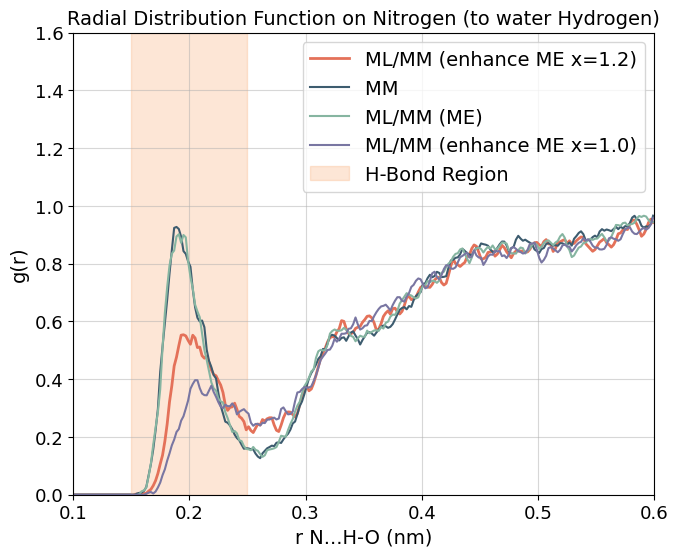

In [14]:
plt.figure(figsize=(7.5, 6))
plt.plot(r_ML_12, g_r_ML_12_smooth, lw=2, label=f'ML/MM (enhance ME x=1.2)',color = '#E47159')
plt.plot(r_MM, g_r_MM_smooth, lw=1.5, label=f'MM ',color = '#3D5C6F')
plt.plot(r_ML_fix, g_r_ML_fix_smooth, lw=1.5, label=f'ML/MM (ME)',color = '#86B5a1')
plt.plot(r_ML_10, g_r_ML_10_smooth, lw=1.5, label=f'ML/MM (enhance ME x=1.0)',color = '#7976a2')

plt.axvspan(0.15, 0.25, color='#f9ae78', alpha=0.3, label='H-Bond Region')
plt.title('Radial Distribution Function on Nitrogen (to water Hydrogen)',fontsize = 14)
plt.xlabel('r N...H-O (nm)',fontsize = 14)
plt.ylabel('g(r)',fontsize = 14)
plt.ylim(0,1.6)
plt.xlim(0.1,0.6)
plt.legend(fontsize = 14)
plt.grid(True, alpha=0.5)
plt.tick_params(axis='y', labelsize=13)
plt.tick_params(axis='x', labelsize=13)
# plt.savefig("Hbond_N_to_H.svg", dpi = 300)
plt.show()

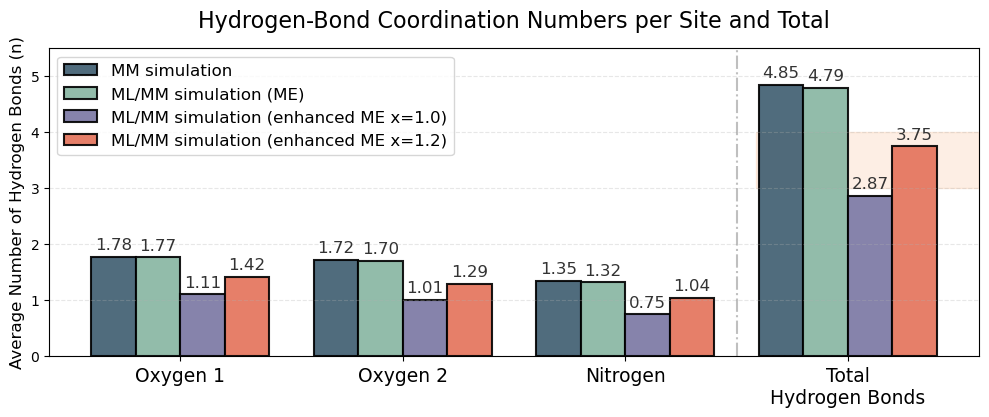

In [ ]:
categories = ['Oxygen 1', 'Oxygen 2', 'Nitrogen', 'Total\nHydrogen Bonds']

# Data for each protocol: [site1, site2, site3, total]
mm = [1.78, 1.72, 1.35, 1.78+1.72+1.35]
ml_fix = [1.75, 1.70, 1.32, 1.77+1.70+1.32]
ml_10 = [1.11, 1.01, 0.75, 1.11+1.01+0.75]
ml_12 = [1.42, 1.29, 1.04, 1.42+1.29+1.04]

x = np.arange(len(categories))
width = 0.2

fig, ax = plt.subplots(figsize=(12, 4))

# Plotting using the colors from your previous plots
rects1 = ax.bar(x - 1.5*width, mm, width, label='MM simulation', color='#3D5C6F', alpha=0.9,edgecolor = 'black', linewidth = 1.5)
rects2 = ax.bar(x - 0.5*width, ml_fix, width, label='ML/MM simulation (ME)', color='#86B5a1', alpha=0.9,edgecolor = 'black', linewidth = 1.5)
rects3 = ax.bar(x + 0.5*width, ml_10, width, label='ML/MM simulation (enhanced ME x=1.0)', color='#7976a2', alpha=0.9,edgecolor = 'black', linewidth = 1.5)
rects4 = ax.bar(x + 1.5*width, ml_12, width, label='ML/MM simulation (enhanced ME x=1.2)', color='#E47159', alpha=0.9,edgecolor = 'black', linewidth = 1.5)

# Formatting
ax.set_ylabel('Average Number of Hydrogen Bonds (n)', fontsize=12)
ax.set_title('Hydrogen-Bond Coordination Numbers per Site and Total', fontsize=16, pad=15)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=13.5)
ax.set_ylim(0, 5.5)
ax.legend(loc='upper left', fontsize=12)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# Add visual separation for the 'Total' section
ax.axvline(x=2.5, color='gray', linestyle='-.', alpha=0.5, linewidth=1.5)

# Add value annotations
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=12, color='#333')

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)
autolabel(rects4)

# Highlight the 3-4 target zone for total H-bonds
ax.axhspan(3.0, 4.0, xmin=0.76, xmax=1.0, color='#f9ae78', alpha=0.2, zorder=0)
# plt.savefig('total_hond.svg',bbox_inches='tight')